# **Health Insurance Premium Prediction using Linear Regression**

**Goal:** Build a Linear Regression model that predicts the health insurance premium (cost) of a person from personal details such as age, BMI and smoking status.

**Dataset:** `insurance.csv`

| Column | Description |
|---|---|
| `age` | Age of the person |
| `sex` | Gender (male / female) |
| `bmi` | Body Mass Index |
| `children` | Number of children covered by the insurance |
| `smoker` | Whether the person smokes (yes / no) |
| `region` | Residential area (northeast, northwest, southeast, southwest) |
| `charges` | Insurance cost billed to the person, used here as the premium. **This is the target we predict.** |

In [28]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


### 1. Import Libraries

We import the libraries needed for data handling, graphs and the Linear Regression model.

In [29]:
# Import the libraries we need

import pandas as pd                  # Read and work with tabular data
import numpy as np                   # Numerical operations
import matplotlib.pyplot as plt      # Graphs and visualizations
import seaborn as sns                # Graphs and visualizations

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 2. Load the Dataset

We read `insurance.csv` into a Pandas DataFrame. In Google Colab, upload the file first and use the path `/content/insurance.csv`.

In [10]:
# Load the dataset

df = pd.read_csv("insurance.csv")
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### 3. Understand the Dataset

Before training a model, we inspect the data. Each row is one person and each column is a detail about that person.

- `info()`: column names, data types and non-null counts
- `describe()`: summary statistics of the numeric columns

In [11]:
# Inspect the dataset

print("Data types and non-null counts:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Summary of numeric columns:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### 4. Data Visualization

Graphs help us find patterns before building the model.

- **Histogram:** how the insurance charges are distributed
- **Scatter plot:** relationship between age and charges
- **Bar chart:** average charges of smokers and non-smokers

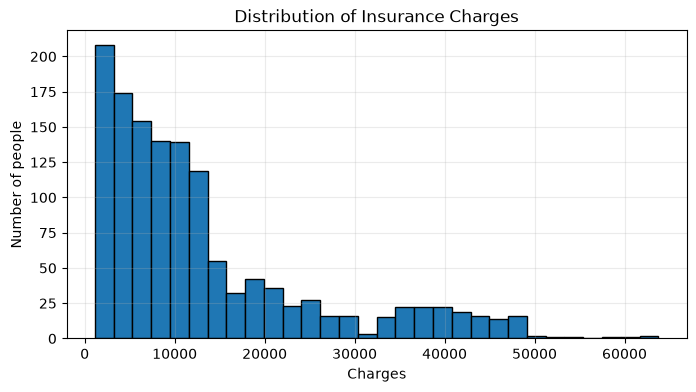

In [12]:
# Histogram of the target column (charges)

plt.figure(figsize=(8, 4))
plt.hist(df["charges"], bins=30, edgecolor="black")
plt.title("Distribution of Insurance Charges")
plt.xlabel("Charges")
plt.ylabel("Number of people")
plt.grid(alpha=0.25)
plt.show()

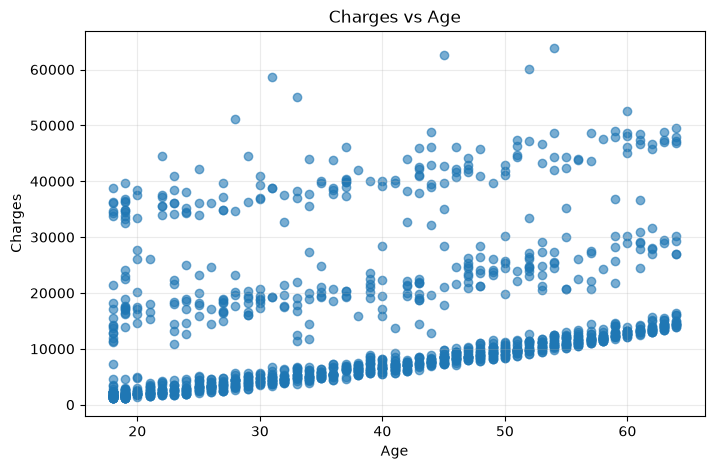

In [13]:
# Scatter plot: age vs charges

plt.figure(figsize=(8, 5))
plt.scatter(df["age"], df["charges"], alpha=0.6)
plt.title("Charges vs Age")
plt.xlabel("Age")
plt.ylabel("Charges")
plt.grid(alpha=0.25)
plt.show()

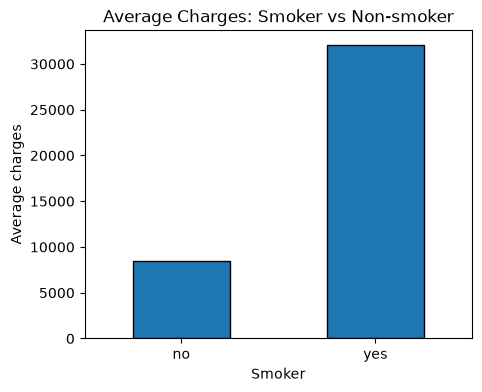

In [14]:
# Bar chart: average charges of smokers and non-smokers

df.groupby("smoker")["charges"].mean().plot(kind="bar", figsize=(5, 4), edgecolor="black")
plt.title("Average Charges: Smoker vs Non-smoker")
plt.xlabel("Smoker")
plt.ylabel("Average charges")
plt.xticks(rotation=0)
plt.show()

### 5. Data Processing

Raw data must be cleaned before it is given to a model. We will:

1. Check for missing values and duplicate rows, and remove the duplicates.
2. Convert the text columns (`sex`, `smoker`, `region`) into numbers using **one-hot encoding**, because the model understands only numbers.

In [15]:
# Data cleaning: check missing values and remove duplicate rows

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:", df.shape)

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1
Dataset shape after removing duplicates: (1337, 7)


In [16]:
# Data encoding: convert categorical columns (sex, smoker, region) into 0/1 columns

df = pd.get_dummies(df, drop_first=True, dtype=int)
df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


**Note:** `drop_first=True` removes one column from each category to avoid duplicate information. For example, `smoker_yes = 1` means the person is a smoker and `0` means a non-smoker.

### 6. Prepare Features and Target

- **Features (`X`):** the input columns the model uses to make a prediction
- **Target (`y`):** the column we want to predict, which is `charges`

In [17]:
# Separate input features (X) and target (y)

X = df.drop("charges", axis=1)
y = df["charges"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1337, 8)
Shape of y: (1337,)


### 7. Train-Test Split

We keep some data aside to test the model on people it has not seen during training.

- **Training set (80%):** used to learn the coefficients
- **Testing set (20%):** used to check how well the model predicts on unseen data

`random_state=42` makes the split the same every time the notebook is run.

In [18]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 1069
Testing examples: 268


### 8. Model Training

With several input features, Linear Regression predicts the charges as:

$$
\hat{y} = b_0 + b_1x_1 + b_2x_2 + \cdots + b_nx_n
$$

Here each $x$ is an input feature (age, bmi, smoker, ...) and each $b$ is a coefficient learned from the training data. `fit()` trains the model by finding the coefficients that minimize the squared difference between actual and predicted charges.

In [19]:
# Create and train the Linear Regression model

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


### 9. Prediction

`predict()` uses the trained model to estimate the charges for the test data. We compare the predicted values with the actual values.

In [20]:
# Predict charges for the test set

y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Charges": y_test.to_numpy(),
    "Predicted Charges": y_pred,
    "Error (Actual - Predicted)": y_test.to_numpy() - y_pred
})

display(comparison.head(10))

,Actual Charges,Predicted Charges,Error (Actual - Predicted)
0,8688.85885,8143.693884,545.164966
1,5708.86700,5737.115683,-28.248683
2,11436.73815,14369.314876,-2932.576726
3,38746.35510,31745.513636,7000.841464
4,4463.20510,8962.386657,-4499.181557
5,9304.70190,13149.722353,-3845.020453
6,38511.62830,30446.760679,8064.867621
7,2150.46900,1453.288813,697.180187
8,7345.72660,10633.018402,-3287.291802
9,10264.44210,11318.943794,-1054.501694


**Predict the premium for a new person**

Enter the details of a new person. The same one-hot encoding is applied so that the columns match the training data. Edit the example values to try different people.

In [21]:
# Predict the premium for a new person (edit the example values)

new_person = pd.DataFrame({
    "age": [30],
    "sex": ["male"],
    "bmi": [27.5],
    "children": [1],
    "smoker": ["no"],
    "region": ["southeast"]
})

# Apply the same encoding and keep the same columns as the training data
new_person = pd.get_dummies(new_person).reindex(columns=X.columns, fill_value=0)

predicted_premium = model.predict(new_person)
print(f"Predicted insurance premium: {predicted_premium[0]:,.2f}")

Predicted insurance premium: 4,710.51


### 10. Model Evaluation

We measure how good the predictions are using four common regression metrics:

- **MAE (Mean Absolute Error):** average absolute difference between actual and predicted charges. Lower is better.
- **MSE (Mean Squared Error):** average squared difference. Large errors are penalized more. Lower is better.
- **RMSE (Root Mean Squared Error):** square root of MSE, in the same units as the charges. Lower is better.
- **R² score:** how much of the variation in charges the model explains. A value close to 1 is better.

In [22]:
# Calculate regression metrics on the test set

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.3f}")

MAE  : 4,177.05
MSE  : 35,478,020.68
RMSE : 5,956.34
R²   : 0.807


### 11. Actual vs Predicted Plot

Each dot is one person from the test set. The dashed line shows perfect predictions, so the closer the dots are to the line, the better the model.

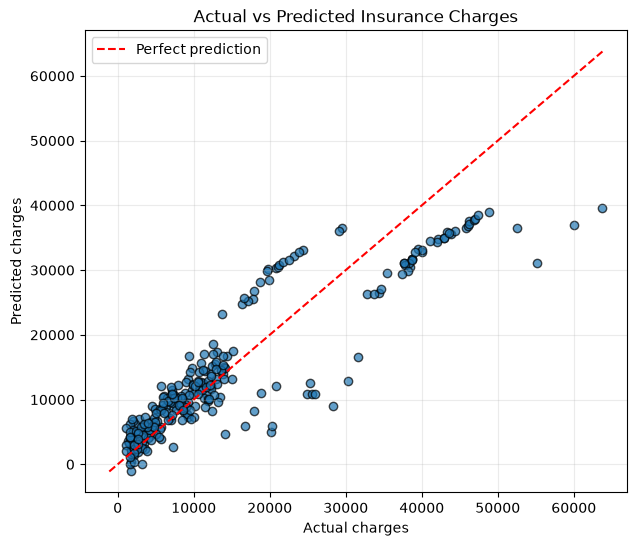

In [23]:
# Scatter plot: actual vs predicted charges

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor="black")

# Reference line for perfect prediction
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], linestyle="--", color="red", label="Perfect prediction")

plt.xlabel("Actual charges")
plt.ylabel("Predicted charges")
plt.title("Actual vs Predicted Insurance Charges")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 11. Variance



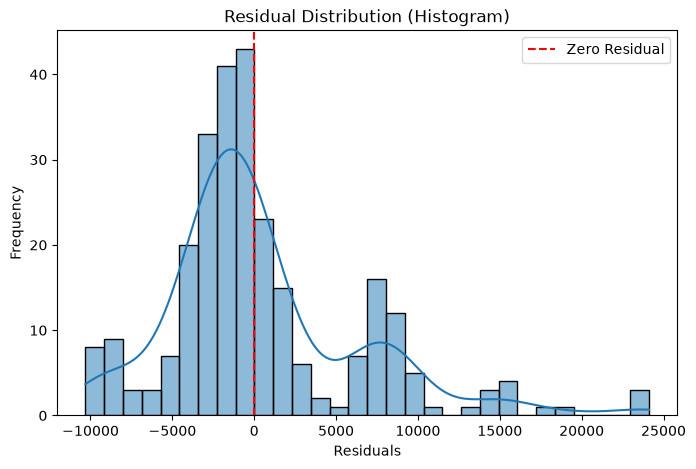

In [30]:

residuals = y_test - y_pred
plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=30, kde=True)

plt.axvline(x=0, color='red', linestyle='--',
            label='Zero Residual')

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution (Histogram)")

plt.legend()
plt.show()